Shape: (459, 500)


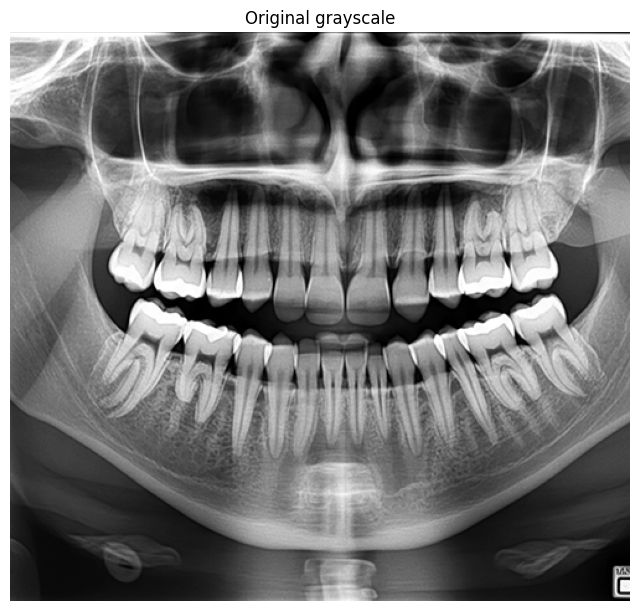

In [3]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

gray = cv2.imread("../data/Xray.png", cv2.IMREAD_GRAYSCALE)
if gray is None:
    raise FileNotFoundError("data/Xray.png not found")
print("Shape:", gray.shape)

plt.figure(figsize=(8, 10))
plt.imshow(gray, cmap="gray")
plt.title("Original grayscale")
plt.axis("off")
plt.show()

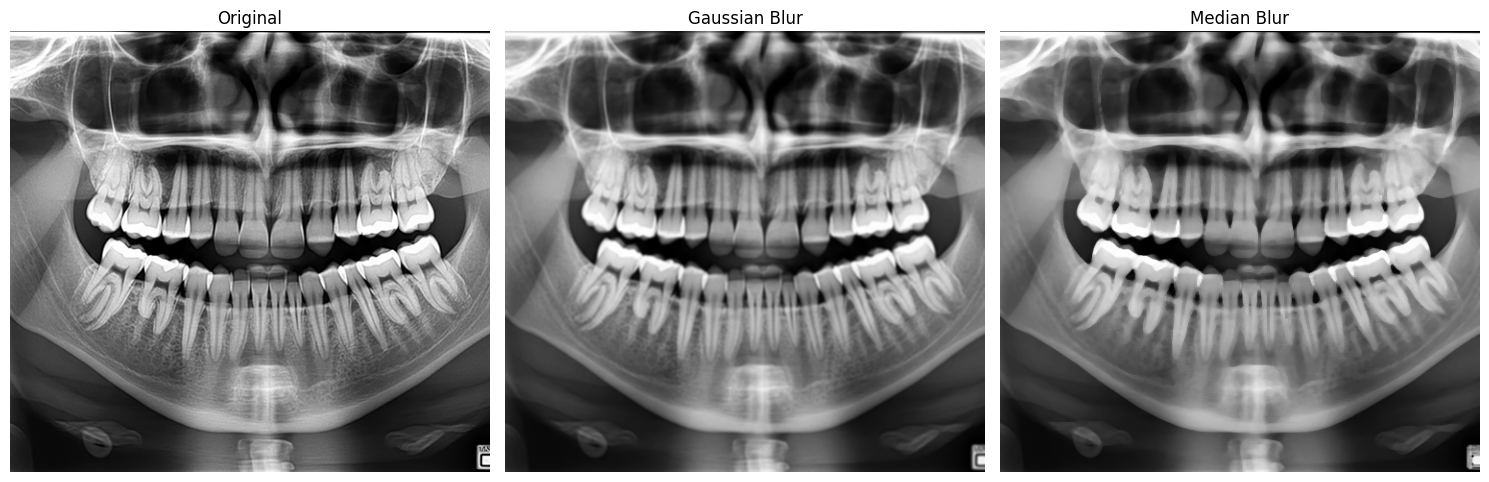

In [4]:
gaussian = cv2.GaussianBlur(gray, (5, 5), 0)
median   = cv2.medianBlur(gray, 5)

fig, axes = plt.subplots(1, 3, figsize=(15, 6))
axes[0].imshow(gray, cmap="gray");     axes[0].set_title("Original")
axes[1].imshow(gaussian, cmap="gray"); axes[1].set_title("Gaussian Blur")
axes[2].imshow(median, cmap="gray");   axes[2].set_title("Median Blur")
for ax in axes: ax.axis("off")
plt.tight_layout()
plt.show()

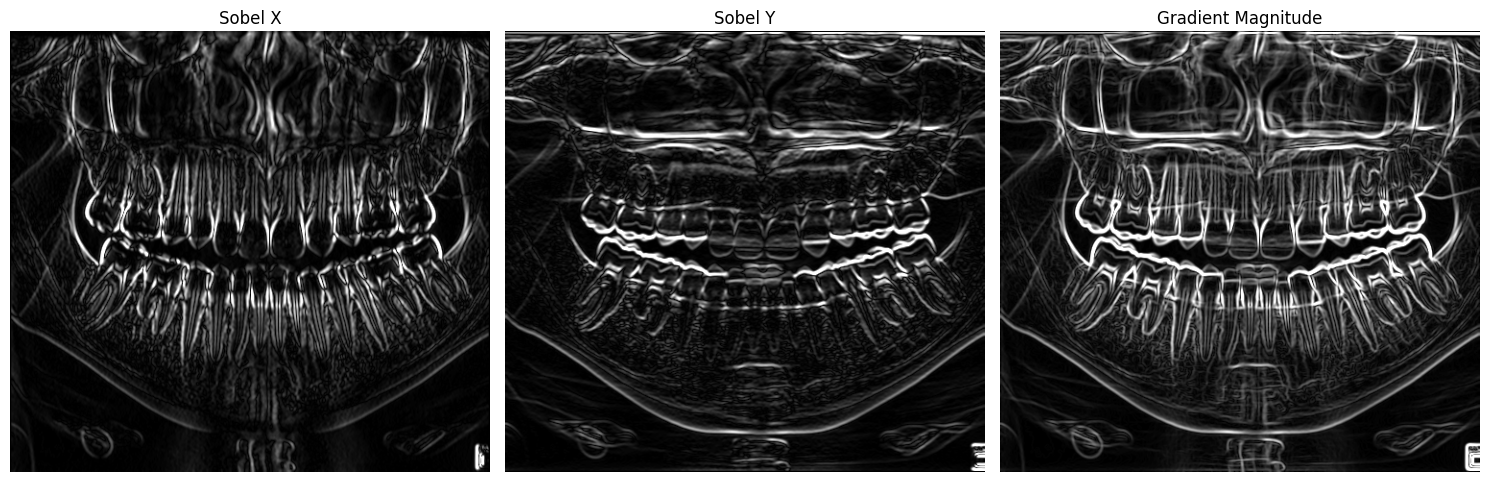

In [5]:
sobel_x = cv2.Sobel(gaussian, cv2.CV_64F, 1, 0, ksize=3)
sobel_y = cv2.Sobel(gaussian, cv2.CV_64F, 0, 1, ksize=3)
sobel_mag = np.uint8(np.clip(np.sqrt(sobel_x**2 + sobel_y**2), 0, 255))

fig, axes = plt.subplots(1, 3, figsize=(15, 6))
axes[0].imshow(np.uint8(np.clip(np.abs(sobel_x), 0, 255)), cmap="gray"); axes[0].set_title("Sobel X")
axes[1].imshow(np.uint8(np.clip(np.abs(sobel_y), 0, 255)), cmap="gray"); axes[1].set_title("Sobel Y")
axes[2].imshow(sobel_mag, cmap="gray");                                   axes[2].set_title("Gradient Magnitude")
for ax in axes: ax.axis("off")
plt.tight_layout()
plt.show()

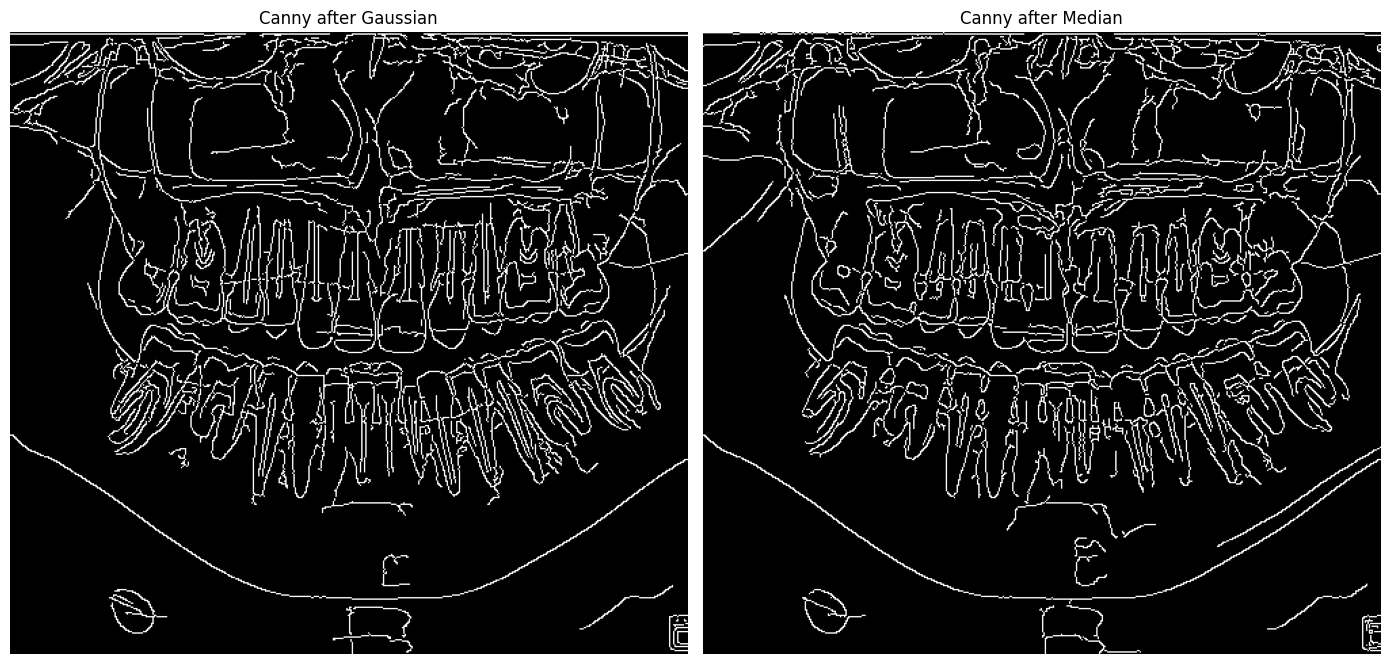

In [6]:
canny_gauss  = cv2.Canny(gaussian, 50, 150)
canny_median = cv2.Canny(median, 50, 150)

fig, axes = plt.subplots(1, 2, figsize=(14, 8))
axes[0].imshow(canny_gauss,  cmap="gray"); axes[0].set_title("Canny after Gaussian")
axes[1].imshow(canny_median, cmap="gray"); axes[1].set_title("Canny after Median")
for ax in axes: ax.axis("off")
plt.tight_layout()
plt.show()

Sobel edge density:              98.62%
Canny (Gaussian) edge density:   8.76%
Canny (Median) edge density:     8.70%


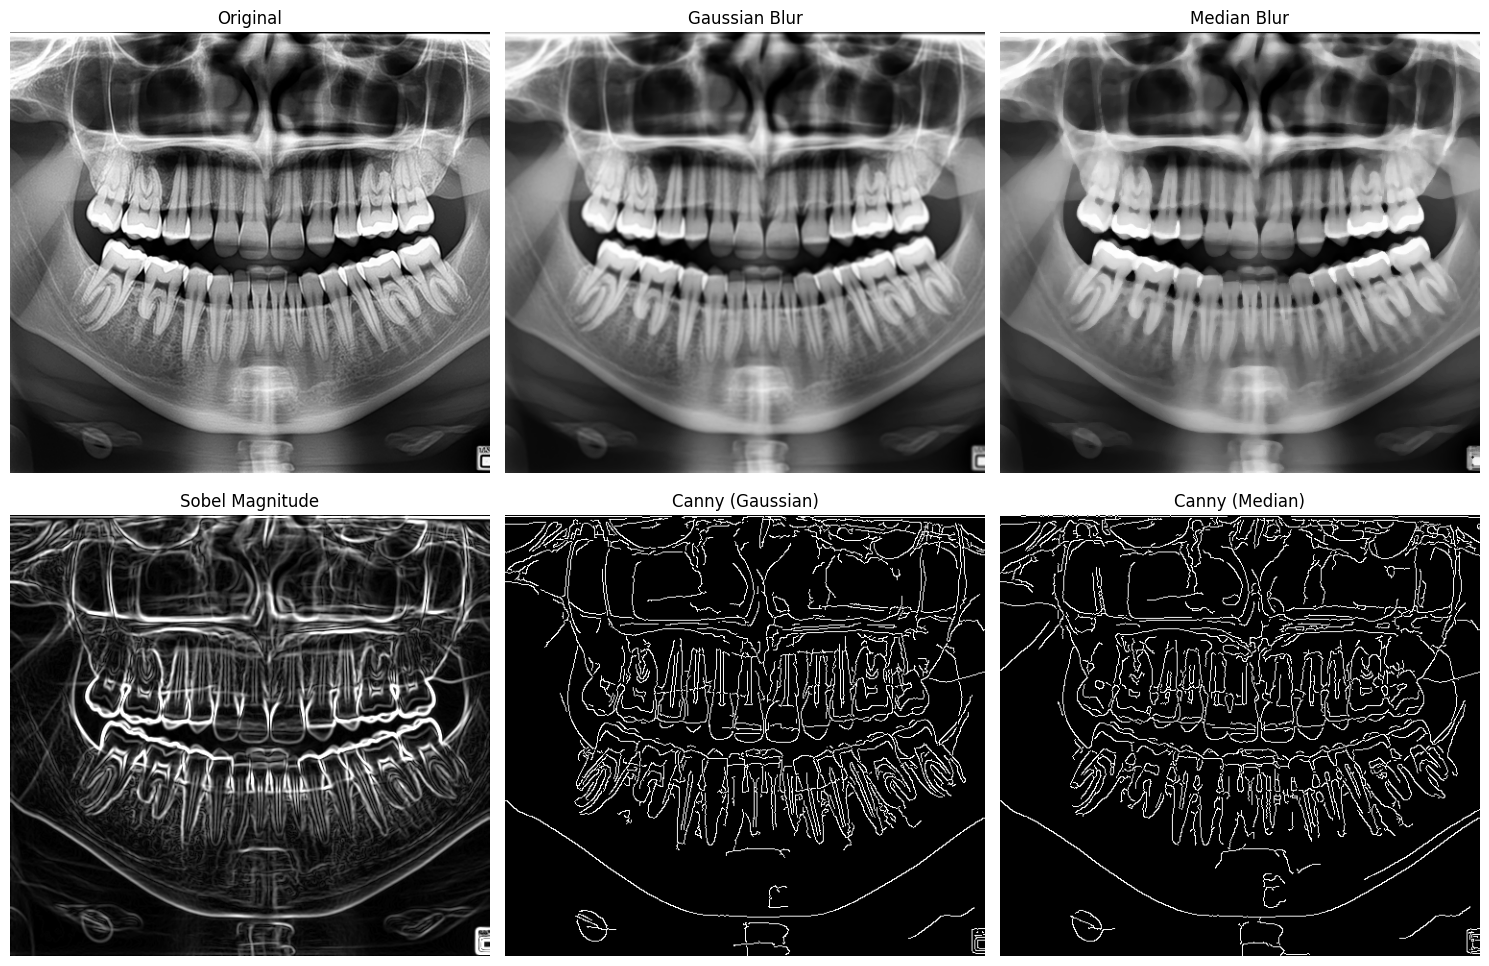

In [7]:
def edge_density(e): return np.count_nonzero(e) / e.size * 100

print(f"Sobel edge density:              {edge_density(sobel_mag):.2f}%")
print(f"Canny (Gaussian) edge density:   {edge_density(canny_gauss):.2f}%")
print(f"Canny (Median) edge density:     {edge_density(canny_median):.2f}%")

fig, axes = plt.subplots(2, 3, figsize=(15, 10))
titles = ["Original", "Gaussian Blur", "Median Blur",
          "Sobel Magnitude", "Canny (Gaussian)", "Canny (Median)"]
images = [gray, gaussian, median, sobel_mag, canny_gauss, canny_median]
for ax, title, im in zip(axes.flat, titles, images):
    ax.imshow(im, cmap="gray"); ax.set_title(title); ax.axis("off")
plt.tight_layout()
plt.savefig("../outputs/task3_edges.png", dpi=150)
plt.show()